# Experiment 000: Image representation

## Objective

Understand how digital images are represented numerically in Python before using them as inouts to a nerural network.

## Questions
- How is an image represented in memory?
- What does each image dimension represent?
- What numerical values are stored in individual pixels?
- How are red, green, and blue channels separated?

In [136]:
from pathlib import Path
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt

In [137]:
import os
from pathlib import Path
default_data_dir = Path.home() / "data" / "shipsnet"

data_dir = Path(
    os.environ.get("SHIPSNET_DATA_DIR", default_data_dir)
)

image_path = next(data_dir.glob("*.png"))

print(image_path)

/home/tone/data/shipsnet/1__20170615_181426_0e0d__-122.32619356968694_37.70869015729537.png


<PIL.PngImagePlugin.PngImageFile image mode=RGB size=80x80 at 0x70A06D871810>
Size: (80, 80)
Mode: RGB


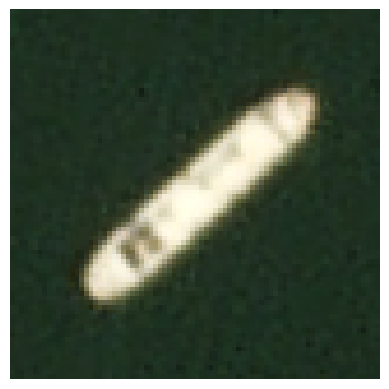

In [138]:
image = Image.open(image_path)

print(image)
print("Size:", image.size)
print("Mode:", image.mode)

plt.imshow(image)
plt.axis("off")
plt.show()

In [139]:
image_array = np.array(image)

print("Array shape:", image_array.shape)
print("Data type:", image_array.dtype)

pixel = image_array[0, 0]
print("Top-left pixel:", pixel)

Array shape: (80, 80, 3)
Data type: uint8
Top-left pixel: [32 55 39]


In [140]:
red_channel = image_array[:, :, 0]
green_channel = image_array[:, :, 1]
blue_channel = image_array[:, :, 2]

print("Red shape", red_channel.shape)
print("Green shape", green_channel.shape)
print("Blue shape", blue_channel.shape)



Red shape (80, 80)
Green shape (80, 80)
Blue shape (80, 80)


[[32 31 27 27 29]
 [29 28 27 28 28]
 [29 27 25 25 26]
 [30 30 23 24 27]
 [32 33 27 29 31]]


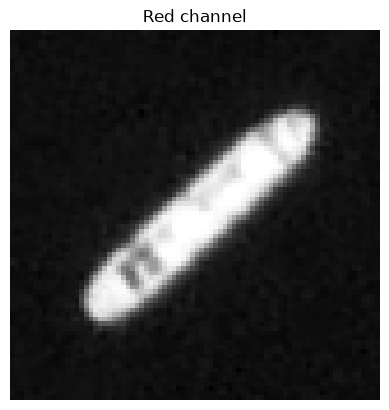

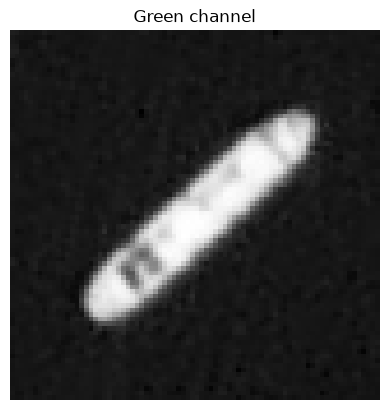

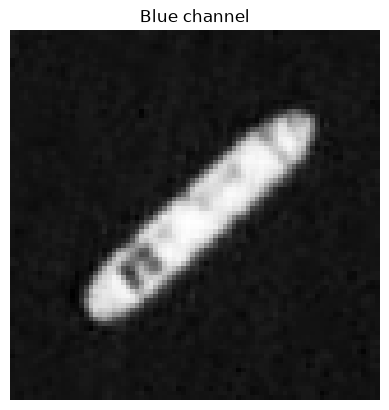

In [141]:
print(red_channel[:5, :5])
plt.imshow(red_channel, cmap="gray")
plt.title("Red channel")
plt.axis("off")
plt.show()

plt.imshow(green_channel, cmap="gray")
plt.title("Green channel")
plt.axis("off")
plt.show()

plt.imshow(blue_channel, cmap="gray")
plt.title("Blue channel")
plt.axis("off")
plt.show()

## Inturpretation 

A ShipsNet image is represented as an 80x80x3 numerical array.
The first two dimensions identity the locaion of a pixel in the image, while the third dimension contains its RGB intensity values.
Each RGB channel cna be represented independently as an 80x80 matrix. Togetherm the three matrices contain 19,200 numerical values that completely describe the image.

In [142]:
row = 10
col = 10

print("Red:", red_channel[row, col])
print("Green:", green_channel[row, col])
print("Blue:", blue_channel[row, col])
print("Original RGB pixel:", image_array[row, col])
print("Number of values:", image_array.size)

Red: 29
Green: 48
Blue: 32
Original RGB pixel: [29 48 32]
Number of values: 19200


In [143]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

PyTorch version: 2.14.0+cu132
CUDA available: True
GPU NVIDIA GeForce RTX 3070 Laptop GPU


In [144]:
image_tensor = torch.from_numpy(image_array)

print("Tensor shape:", image_tensor.shape)
print("Tensor dtype:", image_tensor.dtype)

Tensor shape: torch.Size([80, 80, 3])
Tensor dtype: torch.uint8


In [145]:
image_tensor = image_tensor.permute(2, 0, 1)

print("Reorderd tensor shape:", image_tensor.shape)



Reorderd tensor shape: torch.Size([3, 80, 80])


In [146]:
print("dtype:", image_tensor.dtype)
print("min:", image_tensor.min())
print("max:", image_tensor.max())

dtype: torch.uint8
min: tensor(15, dtype=torch.uint8)
max: tensor(255, dtype=torch.uint8)


In [147]:
image_tensor = image_tensor.float()
print("dtype:", image_tensor.dtype)

image_tensor = image_tensor / 255.0

print("min:", image_tensor.min())
print("max:", image_tensor.max())
print(image_tensor.shape)

dtype: torch.float32
min: tensor(0.0588)
max: tensor(1.)
torch.Size([3, 80, 80])


In [148]:
batched_image = image_tensor.unsqueeze(0)
print(batched_image.shape)

torch.Size([1, 3, 80, 80])


In [149]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

cuda


In [150]:
batched_image = batched_image.to(device)
print(batched_image.device)

cuda:0


In [151]:
import torch.nn as nn

In [152]:
conv = nn.Conv2d(
    in_channels=3,
    out_channels=8,
    kernel_size=3,
    padding=1
)
conv = conv.to(device)

print(conv)
print("Weight shape:", conv.weight.shape)
print("Bias shape:", conv.bias.shape)


Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
Weight shape: torch.Size([8, 3, 3, 3])
Bias shape: torch.Size([8])


In [153]:
feature_maps = conv(batched_image)
print("Input shape:", batched_image.shape)
print("Output shape:", feature_maps.shape)

Input shape: torch.Size([1, 3, 80, 80])
Output shape: torch.Size([1, 8, 80, 80])


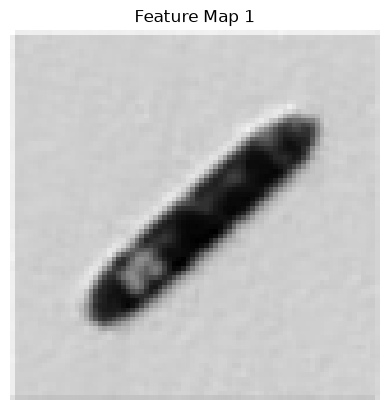

In [154]:
first_feature_map = feature_maps[0, 0].detach().cpu().numpy()

plt.imshow(first_feature_map, cmap="grey")
plt.title("Feature Map 1")
plt.axis("off")
plt.show()

In [155]:
row = 10
col = 10

patch = batched_image[
    0,
    :,
    row - 1:row + 2,
    col - 1:col + 2
]
print("Patch shape:", patch.shape)
print(patch)

Patch shape: torch.Size([3, 3, 3])
tensor([[[0.1176, 0.1098, 0.1059],
         [0.1216, 0.1137, 0.1020],
         [0.1176, 0.1255, 0.1176]],

        [[0.1882, 0.1804, 0.1686],
         [0.1961, 0.1882, 0.1765],
         [0.1922, 0.2078, 0.1961]],

        [[0.1294, 0.1137, 0.1020],
         [0.1294, 0.1255, 0.1098],
         [0.1255, 0.1412, 0.1294]]], device='cuda:0')


In [156]:
filter_weights = conv.weight[0]
filter_bias = conv.bias[0]
print("Filter shape:", filter_weights.shape)
print("Bias:", filter_bias)

Filter shape: torch.Size([3, 3, 3])
Bias: tensor(-0.1509, device='cuda:0', grad_fn=<SelectBackward0>)


In [157]:
manual_value = (patch * filter_weights).sum() + filter_bias

print("Manual calculation:", manual_value)

Manual calculation: tensor(-0.2750, device='cuda:0', grad_fn=<AddBackward0>)


In [158]:
pytorch_value = feature_maps[0, 0, row, col]

print("PyTorch Conv2d:", pytorch_value)
print("Manual result:", manual_value)
print(torch.allclose(manual_value, pytorch_value))

PyTorch Conv2d: tensor(-0.2750, device='cuda:0', grad_fn=<SelectBackward0>)
Manual result: tensor(-0.2750, device='cuda:0', grad_fn=<AddBackward0>)
True


In [159]:
relu = nn.ReLU()
activated_maps = relu(feature_maps)

print("Before ReLU")
print(f"Min: {feature_maps.min().item()}")
print(f"Max: {feature_maps.max().item()}")

print(f"After ReLU")
print(f"Min: {activated_maps.min().item()}")
print(f"Max: {activated_maps.max().item()}")

Before ReLU
Min: -1.0667634010314941
Max: 1.5265882015228271
After ReLU
Min: 0.0
Max: 1.5265882015228271


In [160]:
negative_before = (feature_maps < 0).sum()
negative_after = (activated_maps < 0).sum()

print(f"Negative values before ReLU: {negative_before.item()}")
print(f"Negative values after ReLU {negative_after.item()}")

Negative values before ReLU: 24882
Negative values after ReLU 0


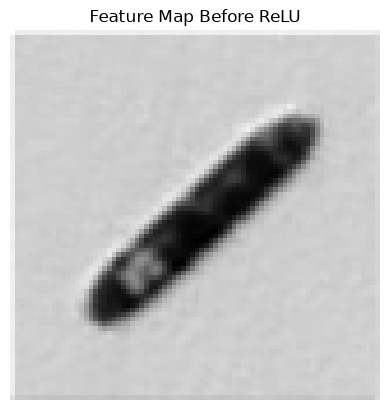

<function matplotlib.pyplot.show(close=None, block=None)>

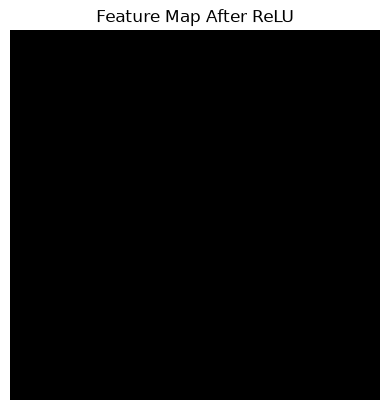

In [161]:
before_relu = feature_maps[0,0].detach().cpu().numpy()
after_relu = activated_maps[0,0].detach().cpu().numpy()

plt.imshow(before_relu, cmap="grey")
plt.title("Feature Map Before ReLU")
plt.axis("off")
plt.show()

plt.imshow(after_relu, cmap="grey")
plt.title("Feature Map After ReLU")
plt.axis("off")
plt.show

In [162]:
pool = nn.MaxPool2d(kernel_size=2, stride=2)

pooled_maps = pool(activated_maps)

print(f"Before pooling: {activated_maps.shape}")
print(f"After pooling: {pooled_maps.shape}")

Before pooling: torch.Size([1, 8, 80, 80])
After pooling: torch.Size([1, 8, 40, 40])


In [163]:
region = activated_maps[0, 0, 0:2, 0:2]

print("2x2 region:")
print(region)

print(f"\nMaximum value: {region.max().item()}")
print(f"Pooling output: {pooled_maps[0, 0, 0, 0].item()}")

2x2 region:
tensor([[0., 0.],
        [0., 0.]], device='cuda:0', grad_fn=<SliceBackward0>)

Maximum value: 0.0
Pooling output: 0.0


In [164]:
model = nn.Sequential(
    nn.Conv2d(
        in_channels=3, 
        out_channels=8,
        kernel_size=3,
        padding=1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),

    nn.Conv2d(
        in_channels=8,
        out_channels=16,
        kernel_size=3,
        padding=1
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2, stride=2),
    nn.Flatten(),

    nn.Linear(
        in_features=16 * 20 * 20,
        out_features=2
    )
)
model = model.to(device)

print(model)

Sequential(
  (0): Conv2d(3, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Flatten(start_dim=1, end_dim=-1)
  (7): Linear(in_features=6400, out_features=2, bias=True)
)


In [165]:
output = model(batched_image)

print(f"Input shape: {batched_image.shape}")
print(f"Output shape: {output.shape}")
print(f"Output: {output}")

Input shape: torch.Size([1, 3, 80, 80])
Output shape: torch.Size([1, 2])
Output: tensor([[-0.0375,  0.0166]], device='cuda:0', grad_fn=<AddmmBackward0>)


In [166]:
x = batched_image
print(f"Input: {x.shape}")

for i, layer in enumerate(model):
    x = layer(x)
    print(f"After layer {i} ({layer.__class__.__name__}): {x.shape}")

Input: torch.Size([1, 3, 80, 80])
After layer 0 (Conv2d): torch.Size([1, 8, 80, 80])
After layer 1 (ReLU): torch.Size([1, 8, 80, 80])
After layer 2 (MaxPool2d): torch.Size([1, 8, 40, 40])
After layer 3 (Conv2d): torch.Size([1, 16, 40, 40])
After layer 4 (ReLU): torch.Size([1, 16, 40, 40])
After layer 5 (MaxPool2d): torch.Size([1, 16, 20, 20])
After layer 6 (Flatten): torch.Size([1, 6400])
After layer 7 (Linear): torch.Size([1, 2])


In [167]:
total_trainable_params = sum(p.numel() for p in model.parameters())

print(f"Total trainable parameters: {total_trainable_params}")

Total trainable parameters: 14194


In [168]:
for name, parameter in model.named_parameters():
    print(f"{name}: {parameter.shape} -> {parameter.numel()} parameters")

0.weight: torch.Size([8, 3, 3, 3]) -> 216 parameters
0.bias: torch.Size([8]) -> 8 parameters
3.weight: torch.Size([16, 8, 3, 3]) -> 1152 parameters
3.bias: torch.Size([16]) -> 16 parameters
7.weight: torch.Size([2, 6400]) -> 12800 parameters
7.bias: torch.Size([2]) -> 2 parameters


In [169]:
label_value = int(image_path.name.split("__")[0])

print(f"Finlename: {image_path.name}")
print(f"Label: {label_value}")

Finlename: 1__20170615_181426_0e0d__-122.32619356968694_37.70869015729537.png
Label: 1


In [170]:
target = torch.tensor([label_value], dtype=torch.long, device=device)

print(f"Target: {target}")
print(f"Target shape: {target.shape}")

Target: tensor([1], device='cuda:0')
Target shape: torch.Size([1])


In [171]:
criterion = nn.CrossEntropyLoss()
output = model(batched_image)
loss = criterion(output, target)

print(f"Raw model output: {output}")
print(f"Correct Class: {target.item()}")
print(f"Loss: {loss.item()}")

Raw model output: tensor([[-0.0375,  0.0166]], device='cuda:0', grad_fn=<AddmmBackward0>)
Correct Class: 1
Loss: 0.6664364337921143


In [172]:
loss.backward()
print(model[0].weight.grad)

tensor([[[[ 0.0000e+00,  0.0000e+00,  0.0000e+00],
          [ 0.0000e+00,  0.0000e+00,  0.0000e+00],
          [ 0.0000e+00,  0.0000e+00,  0.0000e+00]],

         [[ 0.0000e+00,  0.0000e+00,  0.0000e+00],
          [ 0.0000e+00,  0.0000e+00,  0.0000e+00],
          [ 0.0000e+00,  0.0000e+00,  0.0000e+00]],

         [[ 0.0000e+00,  0.0000e+00,  0.0000e+00],
          [ 0.0000e+00,  0.0000e+00,  0.0000e+00],
          [ 0.0000e+00,  0.0000e+00,  0.0000e+00]]],


        [[[-1.4488e-03, -1.1834e-03, -1.1202e-03],
          [-1.5569e-03, -1.1642e-03, -1.5992e-03],
          [-1.2658e-03, -7.9107e-04, -1.2299e-03]],

         [[-1.3783e-03, -9.5444e-04, -1.2110e-03],
          [-1.4535e-03, -8.4378e-04, -1.6976e-03],
          [-1.1400e-03, -4.4381e-04, -1.4647e-03]],

         [[-9.3900e-04, -4.4270e-05, -6.8355e-04],
          [-1.3030e-03, -7.5505e-05, -9.5630e-04],
          [-1.1443e-03, -5.8535e-05, -1.0145e-03]]],


        [[[ 0.0000e+00,  0.0000e+00,  0.0000e+00],
          [ 0.0

In [173]:
grad = model[0].weight.grad

print(f"Gradoemt shape: {grad.shape}")
print(f"Gradient mean: {grad.mean().item()}")
print(f"Gradient min: {grad.min().item()}")
print(f"Gradient max: {grad.max().item()}")

Gradoemt shape: torch.Size([8, 3, 3, 3])
Gradient mean: -0.007514256983995438
Gradient min: -0.08179878443479538
Gradient max: 0.023375440388917923


In [174]:
optimizer = torch.optim.SGD(model.parameters(), lr=0.01)

weight_before = model[0].weight[0, 0, 0, 0].item()
print(f"Weight before update: {weight_before}")

optimizer.step()

weight_after = model[0].weight[0, 0, 0, 0].item()
print(f"Weight after update: {weight_after}")

Weight before update: 0.04467727988958359
Weight after update: 0.04467727988958359


In [175]:
optimizer.zero_grad()

print(model[0].weight.grad)

None


In [176]:
for step in range(10):
    optimizer.zero_grad()

    output = model(batched_image)
    loss = criterion(output, target)

    loss.backward()
    optimizer.step()

    print(f"Step {step + 1}: loss = {loss.item():.4f}")

Step 1: loss = 0.4654
Step 2: loss = 0.3254
Step 3: loss = 0.2221
Step 4: loss = 0.1519
Step 5: loss = 0.1071
Step 6: loss = 0.0788
Step 7: loss = 0.0603
Step 8: loss = 0.0478
Step 9: loss = 0.0390
Step 10: loss = 0.0326


In [177]:
output = model(batched_image)
print(f"Logits: {output}")

Logits: tensor([[-1.7825,  1.7878]], device='cuda:0', grad_fn=<AddmmBackward0>)


In [178]:
probabilities = torch.softmax(output, dim=1)

print(f"Probabilities: {probabilities}")

Probabilities: tensor([[0.0274, 0.9726]], device='cuda:0', grad_fn=<SoftmaxBackward0>)


In [179]:
predicted_class = output.argmax(dim=1)

print(f"True class: {target.item()}")
print(f"Predicted class: {predicted_class.item()}")

True class: 1
Predicted class: 1


In [180]:
from torch.utils.data import Dataset, DataLoader

In [181]:
class ShipsNetDataset(Dataset):
    def __init__(self, data_dir):
        self.data_dir = Path(data_dir)
        self.image_paths = sorted(self.data_dir.glob("*.png"))

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]

        image = Image.open(image_path).convert("RGB")
        image_array = np.array(image)

        image_tensor = torch.from_numpy(image_array)
        image_tensor = image_tensor.permute(2, 0, 1)
        image_tensor = image_tensor.float() / 255.0

        label = int(image_path.name.split("__")[0])
        label_tensor = torch.tensor(label, dtype=torch.long)

        return image_tensor, label_tensor

In [182]:
dataset = ShipsNetDataset(data_dir)

print(f"Dataset size: {len(dataset)}")

Dataset size: 4000


In [183]:
sample_image, sample_label = dataset[0]

print(f"Image shape: {sample_image.shape}")
print(f"Label: {sample_label.item()}")
print(f"Data type: {sample_image.dtype}")
print(f"Min value: {sample_image.min().item()}")
print(f"Max value: {sample_image.max().item()}")

Image shape: torch.Size([3, 80, 80])
Label: 0
Data type: torch.float32
Min value: 0.29411765933036804
Max value: 0.5215686559677124


In [184]:
loader = DataLoader(
    dataset,
    batch_size=32,
    shuffle=True
)

In [185]:
images, labels = next(iter(loader))

print(f"Image batch shape: {images.shape}")
print(f"Label batch shape: {labels.shape}")

Image batch shape: torch.Size([32, 3, 80, 80])
Label batch shape: torch.Size([32])


In [186]:
scene_ids = []

for image_path in dataset.image_paths:
    parts = image_path.name.split("__")
    scene_id = parts[1]
    scene_ids.append(scene_id)

print(f" Total images: {len(scene_ids)}")
print(f"Unique scenes: {len(set(scene_ids))}")

 Total images: 4000
Unique scenes: 434


In [187]:
from collections import Counter

scene_counts = Counter(scene_ids)


In [188]:
scene_labels = {}

for image_path in dataset.image_paths:
    parts = image_path.name.split("__")

    label = int(parts[0])
    scene_id = parts[1]

    if scene_id not in scene_labels:
        scene_labels[scene_id] = []
    scene_labels[scene_id].append(label)

for scene_id, labels in scene_labels.items():
    ship_count = sum(labels)
    no_ship_count = len(labels) - ship_count

In [189]:
scene_summary = []

for scene_id, labels in scene_labels.items():
    ship_count = sum(labels)
    no_ship_count = len(labels) - ship_count
    total_count = len(labels)

    scene_summary.append(
        (scene_id, ship_count, no_ship_count, total_count)
    )
scene_summary.sort(key=lambda x:[3], reverse=True)

In [190]:
print(f"Unique scenes: {len(scene_summary)}")

scene_with_ships = sum(
    1 for _, ship_count, _, _ in scene_summary
    if ship_count > 0
)

print(f"Scenes containing ships: {scene_with_ships}")
print(
    f"Scenes containing no ships: "
    f"{len(scene_summary) - scene_with_ships}"
)

Unique scenes: 434
Scenes containing ships: 214
Scenes containing no ships: 220


In [191]:
scene_sizes = [total for _, _, _, total in scene_summary]

print(f"Smallest scene: {min(scene_sizes)} images")
print(f"Largest scene: {max(scene_sizes)} images")
print(
    f"Average images per scens: "
    f"{sum(scene_sizes) / len(scene_sizes):.2f}"
)

Smallest scene: 1 images
Largest scene: 39 images
Average images per scens: 9.22


In [192]:
num_scenes = len(scene_summary)

scenes_without_ships = num_scenes - scene_with_ships

print(f"Total images: {len(dataset)}")
print(f"Unique scenes: {num_scenes}")
print(f"Scenes containinig ships: {scene_with_ships}")
print(f"Scenes containing no ships: {scenes_without_ships}")

print(f"\nSmallest scene: {min(scene_sizes)} images")
print(f"Largest scens: {max(scene_sizes)} images")
print(
    f"Average scene size:"
    f"{sum(scene_sizes) / len(scene_sizes):.2f} images"
)

Total images: 4000
Unique scenes: 434
Scenes containinig ships: 214
Scenes containing no ships: 220

Smallest scene: 1 images
Largest scens: 39 images
Average scene size:9.22 images


In [193]:
scene_summary.sort(key=lambda x: x[3], reverse=True)

print(f"\n10 largest scenes")
for scene_id, ships, no_ships, total in scene_summary[:10]:
    print(
        f"{scene_id}:"
        f"{total} images"
        f"({ships} ships, {no_ships} no-ships)"
    )


10 largest scenes
20180712_180429_101b:39 images(11 ships, 28 no-ships)
20180712_180755_0f2d:38 images(14 ships, 24 no-ships)
20161218_180845_0e26:37 images(9 ships, 28 no-ships)
20180708_180453_0f28:36 images(12 ships, 24 no-ships)
20170515_180653_1007:34 images(12 ships, 22 no-ships)
20170622_180819_1034:33 images(16 ships, 17 no-ships)
20180708_180908_0f47:32 images(10 ships, 22 no-ships)
20170129_181027_0e1f:30 images(8 ships, 22 no-ships)
20180711_180503_1027:30 images(9 ships, 21 no-ships)
20180712_211331_0f06:30 images(10 ships, 20 no-ships)


In [194]:
mixed_scenes = sum(
    1 for _, ships, no_ships, _ in scene_summary
    if ships > 0 and no_ships > 0
)

ship_only_scenes = sum(
    1 for _, ships, no_ships, _ in scene_summary
    if ships > 0 and no_ships ==0
)

no_ship_only_scenes = sum(
    1 for _, ships, no_ships, _ in scene_summary
    if ships == 0 and no_ships > 0
)
print(f"Mixed scenes: {mixed_scenes}")
print(f"Ship-only scenes: {ship_only_scenes}")
print(f"No-ship-only scenes: {no_ship_only_scenes}")

Mixed scenes: 213
Ship-only scenes: 1
No-ship-only scenes: 220


In [195]:
scene_sizes = [
    total
    for _, _, _, total in scene_summary
]

print(f"Total images represented: {sum(scene_sizes)}")
print(f"Unique scenes: {len(scene_summary)}")
print(f"Smallest scene: {min(scene_sizes)}")
print(f"Largest scene: {max(scene_sizes)}")
print(f"Average scene size: {sum(scene_sizes) / len(scene_sizes):.2f}")

Total images represented: 4000
Unique scenes: 434
Smallest scene: 1
Largest scene: 39
Average scene size: 9.22


In [196]:
import random
split_rng = random.Random(42)

all_scene_ids = list(scene_labels.keys())

num_scenes = len(all_scene_ids)

train_end = int(0.70 * num_scenes)
val_end = int(0.85 * num_scenes)

train_scenes = set(all_scene_ids[:train_end])
val_scenes = set(all_scene_ids[train_end:val_end])
test_scenes = set(all_scene_ids[val_end:])

print(f"Train scenes: {len(train_scenes)}")
print(f"Validation scenes: {len(val_scenes)}")
print(f"Test scenes: {len(test_scenes)}")

Train scenes: 303
Validation scenes: 65
Test scenes: 66


In [197]:
print(f"Train/validation overlap: {len(train_scenes & val_scenes)}")
print(f"Train/test overlap: {len(train_scenes & test_scenes)}")
print(f"Validation/test overlap: {len(val_scenes & test_scenes)}")

Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0


In [198]:
def summarize_split(scene_set):
    total_images = 0
    ship_images = 0

    for scene_id in scene_set:
        labels = scene_labels[scene_id]

        total_images += len(labels)
        ship_images += sum(labels)

    no_ship_images = total_images - ship_images
    ship_rate = ship_images / total_images

    return{
        "scenes": len(scene_set),
        "images": total_images,
        "ships": ship_images,
        "no_ships": no_ship_images,
        "ship_rate": ship_rate
        }

In [199]:
train_stats = summarize_split(train_scenes)
val_stats = summarize_split(val_scenes)
test_stats = summarize_split(test_scenes)

for name, stats in [
    ("Train", train_stats),
    ("Validation", val_stats),
    ("Test", test_stats)
]:
    print(
        f"{name}: "
        f"{stats['scenes']} scenes, "
        f"{stats['images']} images, "
        f"{stats['ships']} ships, "
        f"{stats['no_ships']} no-ships, "
        f"{stats['ship_rate']:.2%} ships "
    )

Train: 303 scenes, 2826 images, 601 ships, 2225 no-ships, 21.27% ships 
Validation: 65 scenes, 417 images, 128 ships, 289 no-ships, 30.70% ships 
Test: 66 scenes, 757 images, 271 ships, 486 no-ships, 35.80% ships 


In [200]:
total_split_images = (
    train_stats["images"]
    + val_stats["images"]
    + test_stats["images"]
)

print(f"Images across splits: {total_split_images}")
print(f"Original dataset size: {len(dataset)}")

Images across splits: 4000
Original dataset size: 4000


In [201]:
for name, stats in[
    ("Train", train_stats),
    ("Validation", val_stats),
    ("Test", test_stats)
]:
    image_fraction = stats["images"] / len(dataset)

    print(
        f"{name}:"
        f"{image_fraction:.2%} of images "
        f"{stats['ship_rate']:.2%} ships "
    )

Train:70.65% of images 21.27% ships 
Validation:10.42% of images 30.70% ships 
Test:18.93% of images 35.80% ships 


## Scene-level dataset split

To reduce risk of data leakage between imagery originating from the same satellite scene, train, validation, and test partitions were created at the scene level rather than the individual-image level.

A fixed random seed of 42 was used for reproducibility

Target split:
- 70% training
- 15% validation
- 15% testing

The resulting splits were checked for:
- scene overlap
- total image count
- class distribution

In [202]:
from sklearn.model_selection import StratifiedGroupKFold

labels = []
groups = []

for image_path in dataset.image_paths:
    parts = image_path.name.split("__")

    labels.append(int(parts[0]))
    groups.append(parts[1])

sgkf = StratifiedGroupKFold(
    n_splits=20,
    shuffle=True,
    random_state=42
)

In [206]:
folds = []

dummy_x = np.zeros(len(labels))

for _, fold_indices in sgkf.split(
    dummy_x,
    labels,
    groups
):
    folds.append(fold_indices)

train_indices = np.concatenate(folds[:14])
val_indices = np.concatenate(folds[14:17])
test_indices = np.concatenate(folds[17:20])

In [207]:
print(f"Train image: {len(train_indices)}")
print(f"Validation images: {len(val_indices)}")
print(f"Test images: {len(test_indices)}")

print(
    f"Total images: "
    f"{len(train_indices) + len(val_indices) + len(test_indices)}"
)

print()

total_images = len(dataset)

print(f"Train fraction: {len(train_indices) / total_images:.2%}")
print(f"Validation fraction: {len(val_indices) / total_images:.2%}")
print(f"Test fraction: {len(test_indices) / total_images:.2%}")

Train image: 2796
Validation images: 620
Test images: 584
Total images: 4000

Train fraction: 69.90%
Validation fraction: 15.50%
Test fraction: 14.60%


In [ ]:
labels_array = np.array(labels)

for name, indices in[
    ("Train", train_indices),
    ("Validation", val_indices),
    ("Test", test_indices),
]:
    split_labels = labels_array[indices]

    ship_count = split_labels.sum()
    total_count = len(split_labels)
    no_ship_count = total_count - ship_count
    ship_rate = ship_count / total_count

    print(
        f"{name}: "
        f"{total_count} images, "
        f"{ship_count} ships, "
        f"{no_ship_count} no-ships, "
        f"{ship_rate:.2%} ships"
    )

Train: 2796 images, 700 ships, 2096 no-ships, 25.04% ships
Validation: 620 images, 158 ships, 462 no-ships, 25.48% ships
Test: 584 images, 142 ships, 442 no-ships, 24.32% ships


In [212]:
groups_array = np.array(groups)

train_groups = set(groups_array[train_indices])
val_groups = set(groups_array[val_indices])
test_groups = set(groups_array[test_indices])

print(f"Train/validation overlap: {len(train_groups & val_groups)}")
print(f"Train/test overlap: {len(train_groups & test_groups)}")
print(f"Validation/test overlap: {len(val_groups & test_groups)}")

Train/validation overlap: 0
Train/test overlap: 0
Validation/test overlap: 0


In [216]:
from torch.utils.data import Subset

train_dataset = Subset(dataset, train_indices.tolist())
val_dataset = Subset(dataset, val_indices.tolist())
test_dataset = Subset(dataset, test_indices.tolist())

print(f"Train samples: {len(train_dataset)}")
print(f"Validation samples: {len(val_dataset)}")
print(f"Test samples: {len(test_dataset)}")

Train samples: 2796
Validation samples: 620
Test samples: 584


In [219]:
batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False
)

In [221]:
images, labels = next(iter(train_loader))

print(f"Images shape: {images.shape}")
print(f"Labels shape: {labels.shape}")
print(f"Image dtype: {images.dtype}")
print(f"Label dtype: {labels.dtype}")
print()
print(labels)

Images shape: torch.Size([32, 3, 80, 80])
Labels shape: torch.Size([32])
Image dtype: torch.float32
Label dtype: torch.int64

tensor([1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 0, 0, 0, 1])


In [222]:
def create_model():
    return nn.Sequential(
        nn.Conv2d(
            in_channels=3,
            out_channels=8,
            kernel_size=3,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Conv2d(
            in_channels=8,
            out_channels=16,
            kernel_size=3,
            padding=1
        ),
        nn.ReLU(),
        nn.MaxPool2d(kernel_size=2, stride=2),

        nn.Flatten(),

        nn.Linear(
            in_features=16 * 20 * 20,
            out_features=2
        )

    )
model = create_model().to(device)

In [223]:
criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

In [224]:
model.train()

running_loss = 0.0
correct = 0
total = 0

for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    optimizer.step()

    running_loss += loss.item() * images.size(0)

    predictions = outputs.argmax(dim=1)

    correct += (predictions == labels).sum().item()
    total += labels.size(0)

train_loss = running_loss / total
train_accuracy = correct / total

print(f"Training loss: {train_loss:.4f}")
print(f"Training accuracy: {train_accuracy:.2%}")

Training loss: 0.4878
Training accuracy: 77.68%


In [227]:
model.eval()

val_running_loss = 0.0
val_correct = 0
val_total = 0
true_positive = 0
true_negative = 0
false_positive = 0
false_negative = 0


with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        val_running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        true_positive +=(
            (predictions == 1) & (labels == 1)
        ).sum().item()

        true_negative +=(
            (predictions == 0) & (labels == 0)
        ).sum().item()

        false_positive += (
            (predictions == 1) & (labels == 0)
        ).sum().item()

        false_negative += (
            (predictions == 0) & (labels == 1)
        ).sum().item()

        val_correct += (predictions == labels).sum().item()
        val_total += labels.size(0)

val_loss = val_running_loss / val_total
val_accuracy = val_correct / val_total

precision = true_positive / (true_positive + false_positive)
recall = true_positive / (true_positive + false_negative)

f1 = 2 * (precision * recall) / (precision + recall)


print(f"Validation loss: {val_loss:.4f}")
print(f"Validation accuracy: {val_accuracy:.2%}")
print(f"True positives: {true_positive}")
print(f"True negatives: {true_negative}")
print(f"False positives: {false_positive}")
print(f"False negatives: {false_negative}")
print(f"Precision: {precision:.2%}")
print(f"Recall: {recall:.2%}")
print(f"F1 score: {f1:.4f}")

Validation loss: 0.3701
Validation accuracy: 85.81%
True positives: 85
True negatives: 447
False positives: 15
False negatives: 73
Precision: 85.00%
Recall: 53.80%
F1 score: 0.6589


In [229]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        correct += (predictions == labels).sum().item()
        total += labels.size(0)

    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    return epoch_loss, epoch_accuracy

In [230]:
def evaluate(model, loader, criterion, device):
    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    true_positive = 0
    true_negative = 0
    false_positive = 0
    false_negative = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            predictions = outputs.argmax(dim=1)

            correct += (predictions == labels).sum().item()
            total += labels.size(0)

            true_positive += (
                (predictions == 1) & (labels == 1)
            ).sum().item()

            true_negative += (
                (predictions == 0) & (labels == 0)
            ).sum().item()

            false_positive += (
                (predictions == 1) & (labels == 0)
            ).sum().item()

            false_negative += (
                (predictions == 0) & (labels == 1)
            ).sum().item()
    
    epoch_loss = running_loss / total
    epoch_accuracy = correct / total

    precision = true_positive / (
        true_positive + false_positive
    )

    recall = true_positive / (
        true_positive + false_negative
    )

    f1 = 2 * (precision * recall) / (
        precision + recall
    )

    return epoch_loss, epoch_accuracy, precision, recall, f1


In [231]:
torch.manual_seed(42)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

In [232]:
model = create_model().to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.SGD(
    model.parameters(),
    lr=0.01
)

In [233]:
train_losses = []
train_accuracies = []

val_losses = []
val_accuracies = []
val_precisions = []
val_recalls = []
val_f1_scores = []

In [234]:
num_epochs = 10

for epoch in range(num_epochs):
    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    (
        val_loss,
        val_accuracy,
        val_precision,
        val_recall,
        val_f1
    ) = evaluate(
        model,
        val_loader,
        criterion,
        device
    )

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    val_losses.append(val_loss)
    val_accuracies.append(val_accuracy)
    val_precisions.append(val_precision)
    val_recalls.append(val_recall)
    val_f1_scores.append(val_f1)

    print(
        f"Epoch {epoch + 1}/{num_epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_accuracy:.2%} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_accuracy:.2%} | "
        f"Precision: {val_precision:.2%} | "
        f"Recall: {val_recall:.2%} | "
        f"F1: {val_f1:.4f}"
    )

Epoch 1/10 | Train loss: 0.5382 | Train acc: 75.00% | Val loss: 0.4902 | Val acc: 74.68% | Precision: 100.00% | Recall: 0.63% | F1: 0.0126
Epoch 2/10 | Train loss: 0.4063 | Train acc: 81.62% | Val loss: 0.3126 | Val acc: 87.10% | Precision: 85.45% | Recall: 59.49% | F1: 0.7015
Epoch 3/10 | Train loss: 0.3320 | Train acc: 85.12% | Val loss: 0.2873 | Val acc: 88.55% | Precision: 75.44% | Recall: 81.65% | F1: 0.7842
Epoch 4/10 | Train loss: 0.3023 | Train acc: 86.70% | Val loss: 0.2482 | Val acc: 90.00% | Precision: 82.00% | Recall: 77.85% | F1: 0.7987
Epoch 5/10 | Train loss: 0.2730 | Train acc: 88.77% | Val loss: 0.2746 | Val acc: 89.68% | Precision: 74.74% | Recall: 89.87% | F1: 0.8161
Epoch 6/10 | Train loss: 0.2554 | Train acc: 89.23% | Val loss: 0.2952 | Val acc: 87.90% | Precision: 70.05% | Recall: 91.77% | F1: 0.7945
Epoch 7/10 | Train loss: 0.2423 | Train acc: 89.38% | Val loss: 0.2406 | Val acc: 90.81% | Precision: 77.60% | Recall: 89.87% | F1: 0.8328
Epoch 8/10 | Train loss: 0.

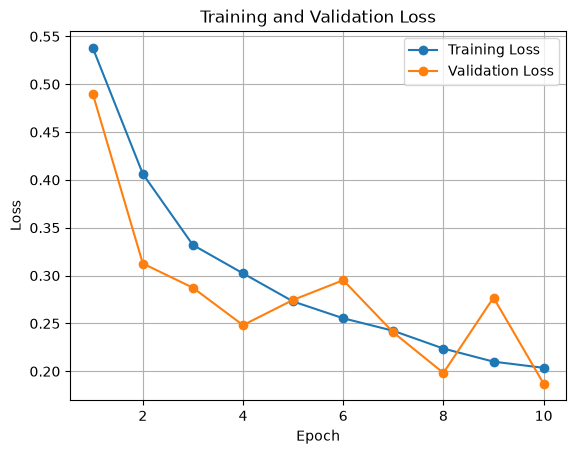

In [235]:
epochs = range(1, num_epochs + 1)

plt.figure()

plt.plot(epochs, train_losses, marker="o", label="Training Loss")
plt.plot(epochs, val_losses, marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid()

plt.show()

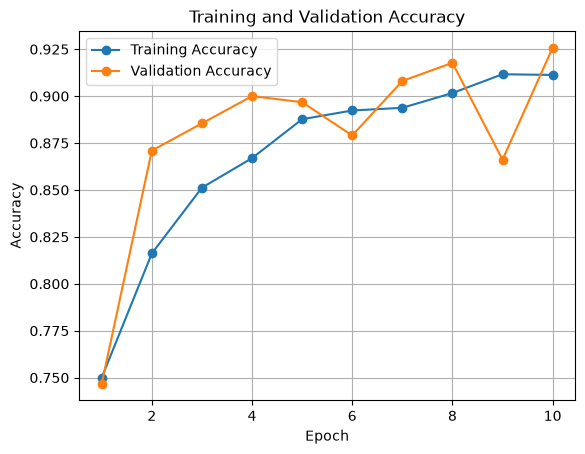

In [236]:
plt.figure()

plt.plot(epochs, train_accuracies, marker="o", label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker="o", label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()

plt.show()

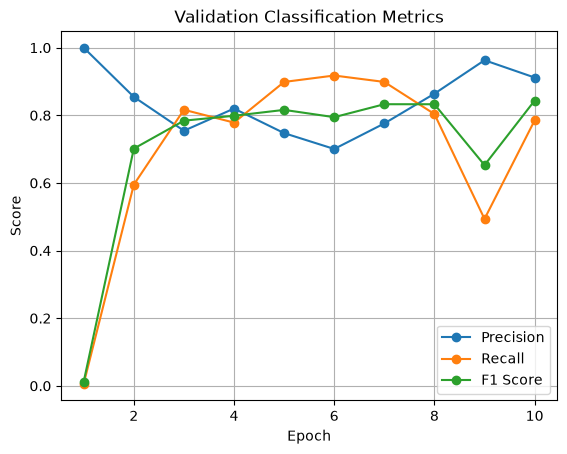

In [237]:
plt.figure()

plt.plot(epochs, val_precisions, marker="o", label="Precision")
plt.plot(epochs, val_recalls, marker="o", label="Recall")
plt.plot(epochs, val_f1_scores, marker="o", label="F1 Score")

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Classification Metrics")
plt.legend()
plt.grid()

plt.show()